In [1]:
import torch
from torch import nn
import matplotlib.pyplot as plt

In [3]:
weight = 0.7
bias = 0.3
start = 0
end = 1
step = 0.02
X = torch.arange(start, end, step).unsqueeze(dim=1)
y = weight * X + bias
X[:10], y[:10]

(tensor([[0.0000],
         [0.0200],
         [0.0400],
         [0.0600],
         [0.0800],
         [0.1000],
         [0.1200],
         [0.1400],
         [0.1600],
         [0.1800]]),
 tensor([[0.3000],
         [0.3140],
         [0.3280],
         [0.3420],
         [0.3560],
         [0.3700],
         [0.3840],
         [0.3980],
         [0.4120],
         [0.4260]]))

In [9]:
train_split = int(0.8 * len(X))
X_train= X[:train_split]
y_train = y[:train_split]
X_test = X[train_split:]
y_test = y[train_split:]
print("training inputs:", len(X_train))
print("training outputs:", len(y_train))
print("testing inputs:", len(X_test))
print("testing outputs:", len(y_test))

training inputs: 40
training outputs: 40
testing inputs: 10
testing outputs: 10


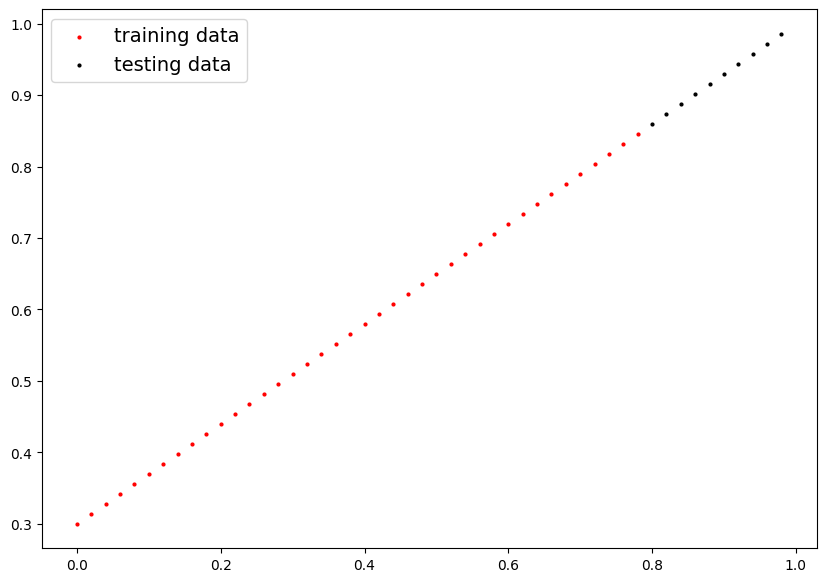

In [7]:
def plot_predictions(train_data=X_train, 
                     train_labels=y_train, 
                     test_data=X_test, 
                     test_labels=y_test, 
                     predictions=None):
  plt.figure(figsize=(10, 7))
  plt.scatter(train_data, train_labels, c="red", s=4, label="training data")
  plt.scatter(test_data, test_labels, c="black", s=4, label="testing data")
  if predictions is not None:
    plt.scatter(test_data, predictions, c="blue", s=4, label="predictions")
  plt.legend(prop={"size": 14});
plot_predictions();

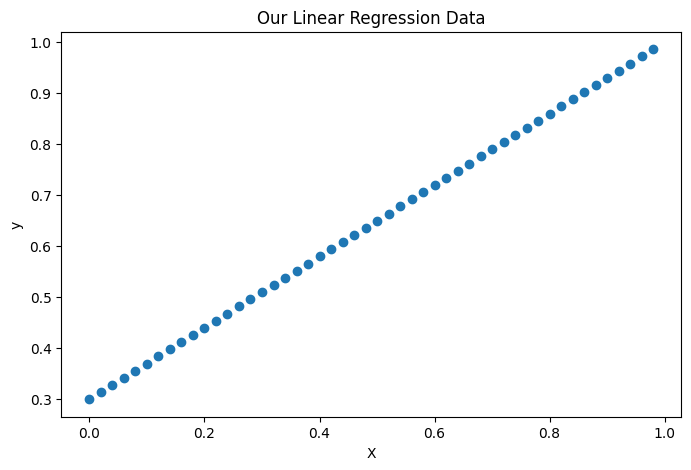

In [8]:
plt.figure(figsize=(8, 5))
plt.scatter(X.numpy(), y.numpy())
plt.xlabel("X")
plt.ylabel("y")
plt.title("Our Linear Regression Data")
plt.show()

In [10]:
class LinearRegressionModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.weights = nn.Parameter(
            torch.randn(1, dtype=torch.float32)
        )
        self.bias = nn.Parameter(
            torch.randn(1, dtype=torch.float32)
        )
    def forward(self, x):
        return self.weights * x + self.bias
torch.manual_seed(42)
model = LinearRegressionModel() 
print("Model:", model)
print("Weights:", model.weights)
print("Bias:", model.bias)
print("Model parameters:", list(model.parameters()))


Model: LinearRegressionModel()
Weights: Parameter containing:
tensor([0.3367], requires_grad=True)
Bias: Parameter containing:
tensor([0.1288], requires_grad=True)
Model parameters: [Parameter containing:
tensor([0.3367], requires_grad=True), Parameter containing:
tensor([0.1288], requires_grad=True)]


In [11]:
with torch.inference_mode():
    y_predictions = model(X_test)
print("Actual values:")
print(y_test[:5])
print("Model predictions:")
print(y_predictions[:5])

Actual values:
tensor([[0.8600],
        [0.8740],
        [0.8880],
        [0.9020],
        [0.9160]])
Model predictions:
tensor([[0.3982],
        [0.4049],
        [0.4116],
        [0.4184],
        [0.4251]])


In [12]:
loss_fn = nn.L1Loss()
with torch.inference_mode():
    y_predictions = model(X_test)
    initial_loss = loss_fn(y_predictions, y_test)
print("Initial loss:", initial_loss.item())

Initial loss: 0.4945361614227295


In [13]:
optimizer = torch.optim.SGD(
    params=model.parameters(),
    lr=0.01
)
print("Optimizer:", optimizer)

Optimizer: SGD (
Parameter Group 0
    dampening: 0
    differentiable: False
    foreach: None
    fused: None
    lr: 0.01
    maximize: False
    momentum: 0
    nesterov: False
    weight_decay: 0
)


In [14]:
epochs = 100
epoch_count = []
loss_values = []
test_loss_values = []
for epoch in range(epochs):
    model.train()
    y_pred = model(X_train)
    loss = loss_fn(y_pred, y_train)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    model.eval()
    with torch.inference_mode():
        test_pred = model(X_test)
        test_loss = loss_fn(test_pred, y_test)
    epoch_count.append(epoch)
    loss_values.append(loss.item())
    test_loss_values.append(test_loss.item())
    if epoch % 10 == 0:
        print(
            f"Epoch: {epoch} | "
            f"Train loss: {loss.item():.4f} | "
            f"Test loss: {test_loss.item():.4f}"
        )
print("\nTraining completed!")
print("Learned weight:", model.weights.item())
print("Learned bias:", model.bias.item())

Epoch: 0 | Train loss: 0.3129 | Test loss: 0.4811
Epoch: 10 | Train loss: 0.1977 | Test loss: 0.3464
Epoch: 20 | Train loss: 0.0891 | Test loss: 0.2173
Epoch: 30 | Train loss: 0.0531 | Test loss: 0.1446
Epoch: 40 | Train loss: 0.0454 | Test loss: 0.1136
Epoch: 50 | Train loss: 0.0417 | Test loss: 0.0992
Epoch: 60 | Train loss: 0.0382 | Test loss: 0.0889
Epoch: 70 | Train loss: 0.0348 | Test loss: 0.0806
Epoch: 80 | Train loss: 0.0313 | Test loss: 0.0723
Epoch: 90 | Train loss: 0.0279 | Test loss: 0.0647

Training completed!
Learned weight: 0.5784404277801514
Learned bias: 0.3513098657131195


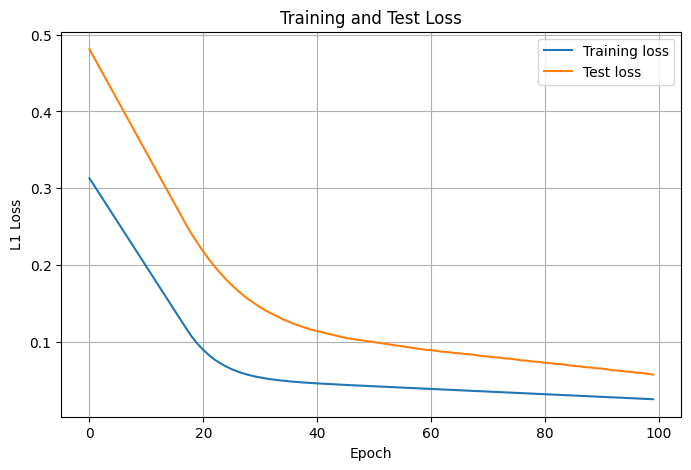

In [15]:
plt.figure(figsize=(8, 5))
plt.plot(epoch_count, loss_values, label="Training loss")
plt.plot(epoch_count, test_loss_values, label="Test loss")
plt.xlabel("Epoch")
plt.ylabel("L1 Loss")
plt.title("Training and Test Loss")
plt.legend()
plt.grid(True)
plt.show()

In [16]:
model.eval()
with torch.inference_mode():
    final_predictions = model(X_test)
print("Actual test values:")
print(y_test.squeeze())
print("\nPredicted test values:")
print(final_predictions.squeeze())
print("\nFinal parameters:")
print("Weight:", model.weights.item())
print("Bias:", model.bias.item())

Actual test values:
tensor([0.8600, 0.8740, 0.8880, 0.9020, 0.9160, 0.9300, 0.9440, 0.9580, 0.9720,
        0.9860])

Predicted test values:
tensor([0.8141, 0.8256, 0.8372, 0.8488, 0.8603, 0.8719, 0.8835, 0.8950, 0.9066,
        0.9182])

Final parameters:
Weight: 0.5784404277801514
Bias: 0.3513098657131195


In [17]:
from pathlib import Path
MODEL_DIR = Path("models")
MODEL_DIR.mkdir(parents=True, exist_ok=True)
MODEL_PATH = MODEL_DIR / "linear_regression_model.pth"
torch.save(model.state_dict(), MODEL_PATH)
print("Model saved to:", MODEL_PATH)

Model saved to: models\linear_regression_model.pth
